Cellule 1: Imports & paths


In [ ]:

from pathlib import Path

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


CATALOGUE = Path("catalogue")
REQUETES = Path("requetes")


test cellule 1


In [5]:
print("Catalogue exists:", CATALOGUE.exists())
print("Requetes exists:", REQUETES.exists())

print("Catalogue path:", CATALOGUE.resolve())
print("Requetes path:", REQUETES.resolve())

Catalogue exists: True
Requetes exists: True
Catalogue path: C:\Users\hp\OneDrive\Desktop\CBIR_ecommerce\backend\day1\catalogue
Requetes path: C:\Users\hp\OneDrive\Desktop\CBIR_ecommerce\backend\day1\requetes


Charger MobileNetV2

In [6]:

model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

Prétraitement d'une image

In [7]:
def prepare_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image = image.resize((224, 224))

    image_array = np.array(image)
    image_array = preprocess_input(image_array)

    return image_array

test


In [8]:
image_path = next(CATALOGUE.glob("camera/*"))

prepared = prepare_image(image_path)

print("Image:", image_path.name)
print("Shape:", prepared.shape)
print("Min:", prepared.min())
print("Max:", prepared.max())

Image: image_0001.jpg
Shape: (224, 224, 3)
Min: -1.0
Max: 1.0


Feature Extraction.

In [9]:
def extract_features(image_path):
    image_array = prepare_image(image_path)

    image_batch = np.expand_dims(image_array, axis=0)

    features = model.predict(image_batch, verbose=0)

    features = features[0]

    return features

test

In [10]:
features = extract_features(image_path)

print("Features shape:", features.shape)
print("First 10 features:", features[:10])

Features shape: (1280,)
First 10 features: [0.01508122 0.01763449 0.76836294 0.00962261 0.03341704 0.2471681
 0.         0.03135508 0.         0.        ]


In [11]:
print("Number of features:", len(features))
print("Data type:", features.dtype)
print("Vector norm:", np.linalg.norm(features))

Number of features: 1280
Data type: float32
Vector norm: 16.400814


L2 Normalization

In [12]:
def normalize_features(features):
    norm = np.linalg.norm(features)

    if norm == 0:
        return features

    return features / norm

Test

In [13]:
normalized_features = normalize_features(features)

print("Normalized vector norm:", np.linalg.norm(normalized_features))
print("First 10 normalized features:", normalized_features[:10])

Normalized vector norm: 1.0
First 10 normalized features: [0.00091954 0.00107522 0.04684907 0.00058672 0.00203752 0.01507048
 0.         0.0019118  0.         0.        ]


Cosine Similarity.

In [14]:
def cosine_similarity(query_features, catalogue_features):
    return np.dot(query_features, catalogue_features)

Extract features for the entire catalogue

In [15]:
catalogue_features = []
catalogue_paths = []

for category in CATALOGUE.iterdir():
    if category.is_dir():
        for image_path in category.iterdir():

            if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                features = extract_features(image_path)
                features = normalize_features(features)

                catalogue_features.append(features)
                catalogue_paths.append(image_path)

catalogue_features = np.array(catalogue_features)

print("Catalogue features shape:", catalogue_features.shape)
print("Number of images:", len(catalogue_paths))

Catalogue features shape: (60, 1280)
Number of images: 60


Search for similar images (Top 5).

In [16]:
def search_similar_images(query_path, top_k=5):

    # Extract query features
    query_features = extract_features(query_path)
    query_features = normalize_features(query_features)

    # Calculate similarity with all catalogue images
    scores = np.dot(catalogue_features, query_features)

    # Get indices of the top K most similar images
    top_indices = np.argsort(scores)[::-1][:top_k]

    # Return paths and similarity scores
    results = []

    for index in top_indices:
        results.append({
            "image_path": catalogue_paths[index],
            "similarity": scores[index]
        })

    return results

test

In [17]:
query_path = next((REQUETES / "camera").glob("*"))

results = search_similar_images(query_path, top_k=5)

print("Query:", query_path.name)

for rank, result in enumerate(results, start=1):
    print(
        rank,
        result["image_path"],
        round(float(result["similarity"]), 4)
    )

Query: image_0006.jpg
1 catalogue\camera\image_0004.jpg 0.6767
2 catalogue\camera\image_0038.jpg 0.6681
3 catalogue\camera\image_0001.jpg 0.6611
4 catalogue\camera\image_0014.jpg 0.6583
5 catalogue\camera\image_0012.jpg 0.6389


Visualize Search Results.

In [18]:
def display_results(query_path, results):

    plt.figure(figsize=(15, 5))

    # Display query image
    plt.subplot(1, len(results) + 1, 1)

    query_image = Image.open(query_path).convert("RGB")
    plt.imshow(query_image)
    plt.title("Query Image")
    plt.axis("off")

    # Display retrieved images
    for rank, result in enumerate(results, start=2):

        image = Image.open(result["image_path"]).convert("RGB")

        plt.subplot(1, len(results) + 1, rank)
        plt.imshow(image)

        score = result["similarity"]

        plt.title(f"Rank {rank - 1}\nScore: {score:.3f}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

test

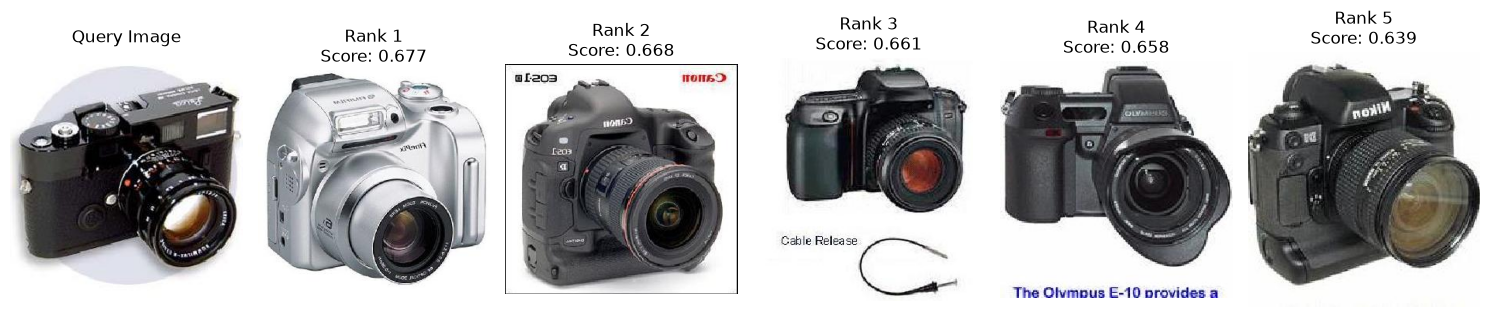

In [19]:
display_results(query_path, results)

Evaluate the CBIR system.

In [20]:
def evaluate_query(query_path, top_k=5):

    results = search_similar_images(query_path, top_k)

    query_category = query_path.parent.name

    relevant_count = 0

    for result in results:
        result_category = result["image_path"].parent.name

        if result_category == query_category:
            relevant_count += 1

    precision = relevant_count / top_k

    return precision

Evaluate all 12 queries

In [21]:
all_precisions = []

for category in REQUETES.iterdir():

    if category.is_dir():

        for query_path in category.iterdir():

            if query_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:

                precision = evaluate_query(query_path, top_k=5)

                all_precisions.append(precision)

                print(
                    query_path.name,
                    "-> Precision@5:",
                    round(precision, 2)
                )

mean_precision = np.mean(all_precisions)

print("\nMean Precision@5:", round(mean_precision, 3))

image_0006.jpg -> Precision@5: 1.0
image_0008.jpg -> Precision@5: 1.0
image_0032.jpg -> Precision@5: 0.8
image_0005.jpg -> Precision@5: 0.8
image_0019.jpg -> Precision@5: 1.0
image_0041.jpg -> Precision@5: 1.0
image_0004.jpg -> Precision@5: 1.0
image_0007.jpg -> Precision@5: 1.0
image_0015.jpg -> Precision@5: 1.0
image_0051.jpg -> Precision@5: 1.0
image_0092.jpg -> Precision@5: 1.0
image_0167.jpg -> Precision@5: 1.0

Mean Precision@5: 0.967


Evaluation per category

In [22]:
category_scores = {}

for category in REQUETES.iterdir():

    if category.is_dir():

        precisions = []

        for query_path in category.iterdir():

            if query_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:

                precision = evaluate_query(query_path, top_k=5)
                precisions.append(precision)

        category_scores[category.name] = np.mean(precisions)

for category, score in category_scores.items():
    print(f"{category}: Precision@5 = {score:.2f}")

camera: Precision@5 = 0.93
headphone: Precision@5 = 0.93
laptop: Precision@5 = 1.00
watch: Precision@5 = 1.00


Save observations

## Day 1 — Results and Observations

### Evaluation Results

The CBIR system was evaluated using 12 query images from four categories: camera, headphone, laptop, and watch.

The evaluation metric was Precision@5.

- Number of queries: 12
- Number of retrieved images per query: 5
- Mean Precision@5: 0.967 (96.7%)
- Total relevant retrieved images: 58 out of 60

### Observations

1. Most queries achieved a Precision@5 of 1.0, meaning all five retrieved images belonged to the same category as the query.
2. Two queries achieved a Precision@5 of 0.8, meaning four out of five retrieved images were relevant.
3. Overall, MobileNetV2 extracted useful visual features for retrieving images from the same category.
4. The experiment uses a small dataset of 60 catalogue images and 12 query images, so the results cannot yet be generalized to a large e-commerce dataset.

### Limitations

- The dataset is small and contains only four product categories.
- Evaluation is based on category matching, not exact product matching.
- MobileNetV2 was pretrained on ImageNet and was not fine-tuned specifically for e-commerce products.
- Similarity scores do not represent

Visualize Precision@5 per category.

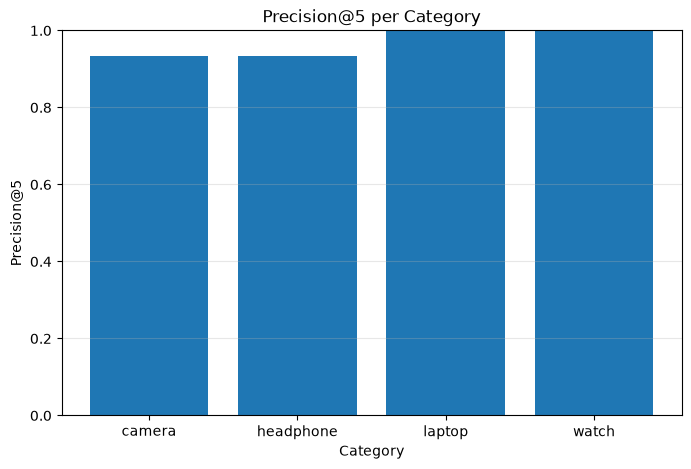

In [23]:
categories = list(category_scores.keys())
scores = list(category_scores.values())

plt.figure(figsize=(8, 5))

plt.bar(categories, scores)

plt.title("Precision@5 per Category")
plt.xlabel("Category")
plt.ylabel("Precision@5")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

### Category-Level Evaluation

The Precision@5 results for each category are:

- Camera: 0.93
- Headphone: 0.93
- Laptop: 1.00
- Watch: 1.00

Laptop and watch achieved the best retrieval performance, with a Precision@5 of 1.00. Camera and headphone achieved 0.93.

These results suggest that MobileNetV2 provides useful visual representations across all four categories in this experiment. However, the dataset is small, so additional testing is required before drawing broader conclusions.


verification mongo

In [ ]:
import sys
import numpy as np
import config ,db, cbir
sys.path.append("backend/") 
         # bach n-importiw config, db, cbir
 
from db.repository import load_vectors
from cbir.preprocess import load_image
from cbir.feature_extractor import extract_batch
 
docs, M = load_vectors()
print(M.shape)                          # (32, 1280)
 
q = extract_batch([load_image("day1/requetes/camera_1.jpg")])[0]
scores = M @ q
for i in np.argsort(-scores)[:5]:
    print(f"{scores[i]:.3f}  {docs[i]['name']}  ({docs[i]['category']})")

ModuleNotFoundError: No module named 'config'